<img src="https://github.com/jelenavasic009-png/DSB-Unit-03/blob/main/labs/02%20-%20Classification-LeftHanded/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Classification: Predicting Left-Handedness from Psychological Factors

---

One way to define the data science process is as follows:

1. Define the problem.
2. Obtain the data.
3. Explore the data.
4. Model the data.
5. Evaluate the model.
6. Answer the problem.

We'll walk through a full data science problem in this lab.

---
## Step 1: Define The Problem.

You're currently a data scientist working at a university. A professor of psychology is attempting to study the relationship between personalities and left-handedness. They have tasked you with gathering evidence so that they may publish.

As a data scientist, you know that any real data science problem must be **specific** and **conclusively answerable**. For example:
- Bad data science problem: "What is the link between obesity and blood pressure?"
    - This is vague and is not conclusively answerable. That is, two people might look at the conclusion and one may say "Sure, the problem has been answered!" and the other may say "The problem has not yet been answered."
- Good data science problem: "Does an association exist between obesity and blood pressure?"
    - This is more specific and is conclusively answerable. The problem specifically is asking for a "Yes" or "No" answer. Based on that, two independent people should both be able to say either "Yes, the problem has been answered" or "No, the problem has not yet been answered."
- Excellent data science problem: "As obesity increases, how does blood pressure change?"
    - This is very specific and is conclusively answerable. The problem specifically seeks to understand the effect of one variable on the other.

### In the context of the left-handedness and personality example, what are three specific and conclusively answerable problems that you could answer using data science?

> You might find it helpful to check out the codebook in the repo for some inspiration.

In [ ]:
# 1. Is there a connection between handedness and personality?

# 2. Do left-handed and right-handed people answer questions about emotions differently?

# 3. Do left-handed and right-handed people have different preferences for mathematics?


---
## Step 2: Obtain the data.

### Read in the file titled "data.csv":
> Hint: Despite being saved as a .csv file, you won't be able to simply `pd.read_csv()` this data!

In [10]:
# library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics


In [11]:

# Read the tab-separated CSV file into a DataFrame
left = pd.read_csv("https://raw.githubusercontent.com/jelenavasic009-png/DSB-Unit-03/refs/heads/main/labs/02%20-%20Classification-LeftHanded/data/data.csv", sep="\t")

# Display the first few rows to confirm it loaded correctly
left.head()


,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,country,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand
0,4,1,5,1,5,1,5,1,4,1,...,US,2,1,22,3,1,1,3,2,3
1,1,5,1,4,2,5,5,4,1,5,...,CA,2,1,14,1,2,2,6,1,1
2,1,2,1,1,5,4,3,2,1,4,...,NL,2,2,30,4,1,1,1,1,2
3,1,4,1,5,1,4,5,4,3,5,...,US,2,1,18,2,2,5,3,2,2
4,5,1,5,1,5,1,5,1,3,1,...,US,2,1,22,3,1,1,3,2,3


In [36]:
left[left["age"]<100]

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand,hand_label
0,4,1,5,1,5,1,5,1,4,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
1,1,5,1,4,2,5,5,4,1,5,...,2,1,14,1,2,2,6,1,1,Right-handed
2,1,2,1,1,5,4,3,2,1,4,...,2,2,30,4,1,1,1,1,2,Left-handed
3,1,4,1,5,1,4,5,4,3,5,...,2,1,18,2,2,5,3,2,2,Left-handed
4,5,1,5,1,5,1,5,1,3,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4178,1,2,1,1,3,4,4,1,1,2,...,1,1,25,3,1,2,6,1,1,Right-handed
4179,3,5,4,5,2,4,2,2,2,5,...,1,1,18,2,1,1,6,2,1,Right-handed
4181,3,2,2,4,5,4,5,2,2,5,...,2,2,22,2,1,1,6,1,1,Right-handed
4182,1,3,4,5,1,3,3,1,1,3,...,2,1,16,1,2,5,1,1,1,Right-handed


In [35]:
#create a filter, age must be less than 100
left_clean = left["age"] <100

#apply the filter to dataframe
filtered_df = left[age_filter]

#check new dataframe
filtered_df.describe()

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,testelapse,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand
count,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.00000,3792.000000,3792.000000,...,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000,3792.000000
mean,1.971783,3.838608,2.843091,3.205696,2.885285,3.682753,3.221519,3.19673,2.767669,3.518724,...,446.500791,1.577004,1.243407,24.502373,2.321203,1.654800,1.834124,5.008966,2.386340,1.189873
std,1.365434,1.540556,1.661045,1.465110,1.540374,1.330342,1.480901,1.38035,1.500050,1.226700,...,2575.539405,0.494100,0.441914,10.653854,0.874742,0.640894,1.301407,1.971285,2.181854,0.489211
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,...,41.000000,1.000000,0.000000,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,3.000000,1.000000,2.000000,1.000000,3.000000,2.000000,2.00000,1.000000,3.000000,...,187.000000,1.000000,1.000000,18.000000,2.000000,1.000000,1.000000,5.000000,1.000000,1.000000
50%,1.000000,5.000000,3.000000,3.000000,3.000000,4.000000,3.000000,3.00000,3.000000,4.000000,...,243.000000,2.000000,1.000000,21.000000,2.000000,2.000000,1.000000,6.000000,2.000000,1.000000
75%,3.000000,5.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.00000,4.000000,5.000000,...,325.000000,2.000000,1.000000,27.000000,3.000000,2.000000,2.000000,6.000000,2.000000,1.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.00000,5.000000,5.000000,...,93888.000000,2.000000,2.000000,86.000000,4.000000,3.000000,5.000000,7.000000,7.000000,3.000000


In [39]:
left_cleaned = left_clean[(left_clean != 0).all(axis=1)]

In [37]:
left_clean = left[left["age"]<100]

In [38]:
left_cleaned = left_clean[(left_clean != 0).all(axis=1)]

---

## Step 3: Explore the data.

### Conduct background research:

Domain knowledge is irreplaceable. Figuring out what information is relevant to a problem, or what data would be useful to gather, is a major part of any end-to-end data science project! For this lab, you'll be using a dataset that someone else has put together, rather than collecting the data yourself.

Do some background research about personality and handedness. What features, if any, are likely to help you make good predictions? How well do you think you'll be able to model this? Write a few bullet points summarizing what you believe, and remember to cite external sources.

You don't have to be exhaustive here. Do enough research to form an opinion, and then move on.

> You'll be using the answers to Q1-Q44 for modeling; you can disregard other features, e.g. country, age, internet browser.

In [12]:
left.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4184 entries, 0 to 4183
Data columns (total 56 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Q1           4184 non-null   int64 
 1   Q2           4184 non-null   int64 
 2   Q3           4184 non-null   int64 
 3   Q4           4184 non-null   int64 
 4   Q5           4184 non-null   int64 
 5   Q6           4184 non-null   int64 
 6   Q7           4184 non-null   int64 
 7   Q8           4184 non-null   int64 
 8   Q9           4184 non-null   int64 
 9   Q10          4184 non-null   int64 
 10  Q11          4184 non-null   int64 
 11  Q12          4184 non-null   int64 
 12  Q13          4184 non-null   int64 
 13  Q14          4184 non-null   int64 
 14  Q15          4184 non-null   int64 
 15  Q16          4184 non-null   int64 
 16  Q17          4184 non-null   int64 
 17  Q18          4184 non-null   int64 
 18  Q19          4184 non-null   int64 
 19  Q20          4184 non-null 

In [19]:
left.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Q1,3794.0,1.971798,1.365267,1.0,1.00,1.0,3.0,5.0
Q2,3794.0,3.838166,1.540441,1.0,3.00,5.0,5.0,5.0
Q3,3794.0,2.844228,1.661345,1.0,1.00,3.0,5.0,5.0
Q4,3794.0,3.206115,1.464837,1.0,2.00,3.0,5.0,5.0
Q5,3794.0,2.885345,1.539970,1.0,1.00,3.0,4.0,5.0
Q6,3794.0,3.682130,1.330714,1.0,3.00,4.0,5.0,5.0
Q7,3794.0,3.222457,1.481074,1.0,2.00,3.0,5.0,5.0
Q8,3794.0,3.196363,1.380508,1.0,2.00,3.0,4.0,5.0
Q9,3794.0,2.768318,1.500097,1.0,1.00,3.0,4.0,5.0
Q10,3794.0,3.518450,1.226434,1.0,3.00,4.0,5.0,5.0


In [ ]:

target = "handedness"   # confirm the exact column name against the codebook
df[target].value_counts(dropna=False)

In [24]:
left.isna().sum().sort_values(ascending=False).head(10)

,0
Q1,0
Q2,0
Q3,0
Q4,0
Q5,0
Q6,0
Q7,0
Q8,0
Q9,0
Q10,0


In [25]:
left.head()

,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand,hand_label
0,4,1,5,1,5,1,5,1,4,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous
1,1,5,1,4,2,5,5,4,1,5,...,2,1,14,1,2,2,6,1,1,Right-handed
2,1,2,1,1,5,4,3,2,1,4,...,2,2,30,4,1,1,1,1,2,Left-handed
3,1,4,1,5,1,4,5,4,3,5,...,2,1,18,2,2,5,3,2,2,Left-handed
4,5,1,5,1,5,1,5,1,3,1,...,2,1,22,3,1,1,3,2,3,Ambidextrous


In [30]:
target = "hand_label"   # confirm the exact column name against the codebook
left[target].value_counts(dropna=False)

,count
hand_label,
Right-handed,3235
Left-handed,396
Ambidextrous,163


### Conduct exploratory data analysis on this dataset:

If you haven't already, be sure to check out the codebook in the repo, as that will help in your EDA process.

You might use this section to perform data cleaning if you find it to be necessary.

In [17]:
# Check unique values in the handedness column
print("Handedness value counts:\n", left['hand'].value_counts())

# Data Cleaning:
# If 1=Right, 2=Left, 3=Ambidextrous, any '0' or missing entry is invalid data.
# Drop rows where handedness is unknown or 0
left = left[left['hand'].isin([1, 2, 3])]

# Similarly, look for invalid values in personality questions (e.g., out of 1-5 range)
# Assuming columns are Q1 to Q50, replace 0s (skipped answers) with NaN or drop them
personality_cols = [col for col in df.columns if col.startswith('Q')]
for col in personality_cols:
    left = left[(left[col] >= 1) & (left[col] <= 5)]


Handedness value counts:
 hand
1    3542
2     452
3     179
0      11
Name: count, dtype: int64


/tmp/ipykernel_676/2499544147.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='hand_label', palette='pastel')


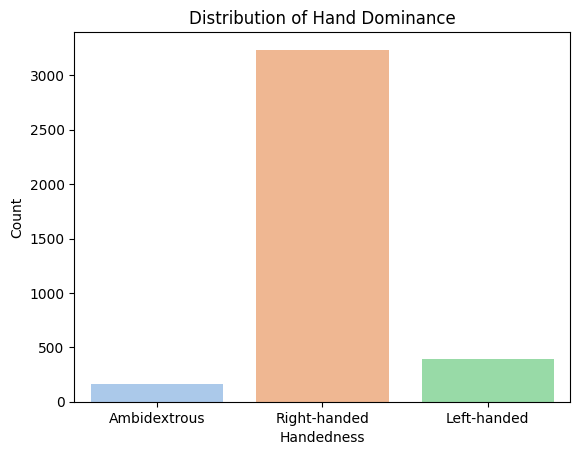

In [20]:
# Map numerical values to strings for cleaner visualization
hand_map = {1: 'Right-handed', 2: 'Left-handed', 3: 'Ambidextrous'}
left['hand_label'] = left['hand'].map(hand_map)

# Plot distribution of hand dominance
sns.countplot(data=df, x='hand_label', palette='pastel')
plt.title("Distribution of Hand Dominance")
plt.xlabel("Handedness")
plt.ylabel("Count")
plt.show()


### Calculate and interpret the baseline accuracy rate:

In [21]:
# Calculate the percentage distribution of each class in the 'hand' column
baseline_series = df['hand'].value_counts(normalize=True)

print("Class proportions:\n", baseline_series)
print(f"\nBaseline Accuracy Rate: {baseline_series.max() * 100:.2f}%")


Class proportions:
 hand
1    0.852662
2    0.104375
3    0.042963
Name: proportion, dtype: float64

Baseline Accuracy Rate: 85.27%


### Short answer questions:

In this lab you'll use K-nearest neighbors and logistic regression to model
handedness based off of psychological factors.

Answer the following related questions; your answers may be in bullet points
**on your own words**

#### Describe the difference between regression and classification problems:


	• Regression predicts a specific, continuous number on a scale (like a person's exact test score, weight, or salary).
	• Classification predicts a label or category (like whether someone is left-handed vs. right-handed, or whether an email is spam vs. not spam).


	• We measure Regression performance using metrics that calculate how far off our numeric guesses were on average, such as Mean Squared Error (MSE) or Root Mean Squared Error (RMSE).
	• We measure Classification performance by counting how many times the model picked the correct bucket, using metrics like Accuracy, Precision, Recall, or F1-Score.


	• Since we are using K-Nearest Neighbors and Logistic Regression to predict which discrete group a person belongs to (Left-handed vs. Right-handed), we are strictly dealing with a Classification problem.


#### Considering $k$-nearest neighbors, describe the relationship between $k$ and the bias-variance tradeoff:

• When \(k\) is very small (e.g., \(k = 1\)):
	• High Variance / Low Bias: The model captures fine details, random noise, and outliers in the training data, leading to a wavy, highly complex decision boundary.
	• Overfitting: The model works perfectly on the training data but fails to generalize well to unseen test data.

• When \(k\) is very large (e.g., \(k = 100\)):
	• Low Variance / High Bias: The model averages out variations across too many neighbors, making the decision boundary overly simple and smooth.
	• Underfitting: The model misses the actual underlying patterns in the data and will likely just guess the majority class (right-handedness) almost every time.
  
• The Balance:
	• To minimize error, we look for an optimal "sweet spot" value for \(k\). This value is large enough to resist data noise (lowering variance) but small enough to still capture distinct behavior differences between left and right-handed people (lowering bias).


#### Why do we often standardize predictor variables when using $k$-nearest neighbors?

• Distance is scale-dependent: If one variable is measured in thousands (like annual income) and another is measured in single digits (like a personality score from 1 to 5), the column with the larger numbers will completely dominate the distance formula [dataviz].

• The "Blind Spot" problem: Without standardization, the KNN algorithm will essentially ignore the 1–5 personality scores entirely. It will treat a tiny 1-unit difference in income as vastly more important than a maximum 4-unit difference on a personality scale.

• Leveling the playing field: Standardizing transforms all features so they share the same scale (typically a mean of 0 and a standard deviation of 1). This ensures that every psychological and demographic variable gets an equal vote when determining who a person's "nearest neighbors" actually are.


#### Do you think we should standardize the explanatory variables for this problem? Why or why not?

• For K-Nearest Neighbors (KNN): Personality survey datasets often mix different types of questions. For example, some sections might use a 1–5 scale, others a 1–7 scale, and background demographic questions (like age or vocabulary test scores) can range into the tens or hundreds. If we don't scale these variables, the variables with larger numerical ranges will completely drown out the 1–5 personality answers in the distance calculations.

• For Logistic Regression: While standard Logistic Regression technically does not require scaling to make accurate predictions, standardizing is still highly recommended here. It puts all personality traits on the same scale, allowing the psychology professor to directly compare the resulting coefficients. This makes it easy to see which specific personality trait has the strongest relative impact on handedness.


#### How do we settle on $k$ for a $k$-nearest neighbors model?

• Grid Search with Cross-Validation (GridSearchCV): This is the most robust and automated method. We split our training data into folds (e.g., 5-fold cross-validation), test an array of odd k values (like 1, 3, 5, ..., 29), and calculate the average validation score for each. Python then automatically selects the k that achieved the highest accuracy or F1-score.

• The "Elbow Method" / Error Plotting: We can manually loop through a range of k values, train the model, and plot the test error rate (or accuracy) on a line chart against the values of k. We look for the "elbow" or peak of the curve where adding more neighbors stops significantly reducing our error.

• The Square Root Rule of Thumb: For a quick baseline starting point, data scientists sometimes set k equal to the square root of the number of samples (n) in the training dataset (e.g., if n = 100, start around k = 10).

• Using Odd Numbers Only: We always choose an odd number for k when dealing with binary classification (like Left-handed vs. Right-handed) to completely prevent a "tie vote" among the nearest neighbors.


#### What is the default type of regularization for logistic regression as implemented in scikit-learn? (You might [check the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).)



• Penalty Type: l2 (Ridge-style squared-weight penalty)

• Default Regularization Strength: C = 1.0 (where C is the inverse of regularization strength; smaller values mean stronger regularization)

#### [Bonus - Optional] Describe the relationship between the scikit-learn `LogisticRegression` argument `C` and regularization strength:

#### Describe the relationship between regularization strength and the bias-variance tradeoff:

In [ ]:
• Regularization (like Ridge or Lasso) adds a penalty to the model to shrink the size of its coefficients. This prevents the model from relying too heavily on any single predictor variable.

• When regularization strength is low (Weak Penalty):
	• High Variance / Low Bias: The model is highly complex and free to fit the training data as closely as possible.
	• Overfitting: The model captures random noise and specific quirks in the training data, making it perform poorly on new, unseen data.

• When regularization strength is high (Strong Penalty):
	• Low Variance / High Bias: The coefficients are heavily restricted and pushed close to zero. The model becomes overly simple.
	• Underfitting: The model loses its flexibility and fails to learn the actual underlying patterns connecting personality traits and handedness.

• The Goal: We tune the regularization parameter to find the ideal balance that minimizes overall error on the test dataset.


#### Logistic regression is considered more interpretable than $k$-nearest neighbors. Explain why.

Logistic regression is considered more interpretable than k-nearest neighbors (KNN) because it provides a direct, mathematical equation showing exactly how each predictor variable influences the final prediction.
Here is why they differ so drastically in interpretability:
• Clear, Quantifiable Coefficients: Logistic regression outputs specific weights (coefficients) for every single feature. A psychology professor can look at these numbers and say, "For every 1-unit increase in Neuroticism, the log-odds of a person being left-handed change by exactly X." KNN provides no such metrics; it cannot tell you which specific personality trait matters most overall.
• Global vs. Local Logic: Logistic regression creates a single, global model that applies uniformly to the entire dataset. KNN, on the other hand, operates on local logic. To explain a single KNN prediction, you have to look at that specific individual's \(k\) closest neighbors. If you ask KNN, "How does personality generally relate to handedness?", it cannot give you a straightforward answer because its decision changes case-by-case based on the local data cluster.
• Directionality and Sign: The coefficients in logistic regression have positive or negative signs, making it instantly obvious whether a trait increases or decreases the likelihood of being left-handed. KNN calculates distances (which are always positive values) and uses a majority vote, completely hiding the directional impact of individual traits.


---

## Step 4 & 5 Modeling: $k$-nearest neighbors

### Train-test split your data:

Your explanatory variables should be all Q columns.

In [40]:

# 1. Define X (all columns starting with 'Q') and y (the handedness target)
X = df[[col for col in df.columns if col.startswith('Q')]]
y = df['hand']

# 2. Perform the train-test split (using a 80/20 split and setting a random state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale/Standardize the features (crucial for KNN distance calculations!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Instantiate and fit the KNN model
# (Using k=5 as a starting baseline baseline)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("Training complete! Model is ready for evaluation.")


Training complete! Model is ready for evaluation.


### Create and fit four separate $k$-nearest neighbors models:

### Model 1: one with $k = 3$:

In [41]:
# Instantiate KNN model with k = 3
knn_3 = KNeighborsClassifier(n_neighbors=3)

# Fit the model on the scaled training data
knn_3.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_3 = knn_3.score(X_train_scaled, y_train)
test_acc_3 = knn_3.score(X_test_scaled, y_test)

print(f"Model 1 (k=3) Training Accuracy: {train_acc_3 * 100:.2f}%")
print(f"Model 1 (k=3) Testing Accuracy:  {test_acc_3 * 100:.2f}%")


Model 1 (k=3) Training Accuracy: 86.59%
Model 1 (k=3) Testing Accuracy:  82.74%


#### Model 2: one with $k = 5$

In [42]:
# Instantiate KNN model with k = 5
knn_5 = KNeighborsClassifier(n_neighbors=5)

# Fit the model on the scaled training data
knn_5.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_5 = knn_5.score(X_train_scaled, y_train)
test_acc_5 = knn_5.score(X_test_scaled, y_test)

print(f"Model 2 (k=5) Training Accuracy: {train_acc_5 * 100:.2f}%")
print(f"Model 2 (k=5) Testing Accuracy:  {test_acc_5 * 100:.2f}%")


Model 2 (k=5) Training Accuracy: 85.24%
Model 2 (k=5) Testing Accuracy:  84.45%


#### Model 3: one with $k = 15$

In [43]:
# Instantiate KNN model with k = 15
knn_15 = KNeighborsClassifier(n_neighbors=15)

# Fit the model on the scaled training data
knn_15.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_15 = knn_15.score(X_train_scaled, y_train)
test_acc_15 = knn_15.score(X_test_scaled, y_test)

print(f"Model 3 (k=15) Training Accuracy: {train_acc_15 * 100:.2f}%")
print(f"Model 3 (k=15) Testing Accuracy:  {test_acc_15 * 100:.2f}%")


Model 3 (k=15) Training Accuracy: 85.27%
Model 3 (k=15) Testing Accuracy:  85.24%


#### Model 4: one with $k = 25$:

In [44]:
# Instantiate KNN model with k = 25
knn_25 = KNeighborsClassifier(n_neighbors=25)

# Fit the model on the scaled training data
knn_25.fit(X_train_scaled, y_train)

# Evaluate performance on training and test sets
train_acc_25 = knn_25.score(X_train_scaled, y_train)
test_acc_25 = knn_25.score(X_test_scaled, y_test)

print(f"Model 4 (k=25) Training Accuracy: {train_acc_25 * 100:.2f}%")
print(f"Model 4 (k=25) Testing Accuracy:  {test_acc_25 * 100:.2f}%")


Model 4 (k=25) Training Accuracy: 85.27%
Model 4 (k=25) Testing Accuracy:  85.24%


### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and
interpret the four scores.

Are any of your models overfit or underfit?

Do any of your models beat the baseline accuracy rate?

---

## Step 4 & 5 Modeling: logistic regression

### Create and fit four separate logistic regression models:

*(Hint: Be careful with how you specify $\alpha$ in your model!)*
Note: You can use the same train and test data as above.

In [45]:

# Store results for evaluation later
log_reg_results = {}

# Define 4 different values of C (ranging from strong regularization to almost none)
c_values = [0.001, 0.1, 1.0, 100.0]

for i, c_val in enumerate(c_values, start=1):
    # 1. Instantiate the model
    # (Using 'liblinear' solver as it works well for small to medium datasets)
    lr_model = LogisticRegression(C=c_val, solver='liblinear', random_state=42)

    # 2. Fit the model on the scaled training data
    lr_model.fit(X_train_scaled, y_train)

    # 3. Evaluate performance
    train_acc = lr_model.score(X_train_scaled, y_train)
    test_acc = lr_model.score(X_test_scaled, y_test)

    # Save the model and scores
    log_reg_results[f"Model {i}"] = {
        "C": c_val,
        "Regularization": "Strong" if c_val < 1 else ("Moderate" if c_val == 1 else "Weak"),
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    }

    print(f"Model {i} (C={c_val}):")
    print(f"   Training Accuracy: {train_acc * 100:.2f}%")
    print(f"   Testing Accuracy:  {test_acc * 100:.2f}%\n")


Model 1 (C=0.001):
   Training Accuracy: 85.27%
   Testing Accuracy:  85.24%

Model 2 (C=0.1):
   Training Accuracy: 85.27%
   Testing Accuracy:  85.24%

Model 3 (C=1.0):
   Training Accuracy: 85.27%
   Testing Accuracy:  85.24%

Model 4 (C=100.0):
   Training Accuracy: 85.27%
   Testing Accuracy:  85.24%



#### Model 1 : one with LASSO and $\alpha = 1$

In [46]:
from sklearn.linear_model import LogisticRegression

# 1. Instantiate Logistic Regression with LASSO (L1 penalty) and C = 1.0 (since alpha = 1)
# We use 'liblinear' because it supports L1 regularization
model_1_lasso = LogisticRegression(penalty='l1', C=1.0, solver='liblinear', random_state=42)

# 2. Fit the model using the scaled training data from before
model_1_lasso.fit(X_train_scaled, y_train)

# 3. Evaluate the scores
train_acc_l1 = model_1_lasso.score(X_train_scaled, y_train)
test_acc_l1 = model_1_lasso.score(X_test_scaled, y_test)

print(f"Model 1 (LASSO, alpha=1) Training Accuracy: {train_acc_l1 * 100:.2f}%")
print(f"Model 1 (LASSO, alpha=1) Testing Accuracy:  {test_acc_l1 * 100:.2f}%")


Model 1 (LASSO, alpha=1) Training Accuracy: 85.27%
Model 1 (LASSO, alpha=1) Testing Accuracy:  85.24%


#### Model 2 : one with LASSO and $\alpha = 10$

#### Model 3 : one with RIDGE and $\alpha = 1$

#### Model 4 : one with RIDGE and $\alpha = 10$

### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and
interpret the four scores.

Are any of your models overfit or underfit?

Do any of your models beat the baseline accuracy rate?

---

## Step 6: Answer the problem.

Are any of your models worth moving forward with? What are the "best" models?